<a href="https://colab.research.google.com/github/AleBJ911/DeepLearning/blob/main/ProyectoEuroSatDataset/Avance2_ProyectoFinal_AlejandraBustos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto final — Segundo avance: CNN desde cero, transfer learning y fine-tuning en EuroSAT

Se aplican y comparan las tres técnicas propuestas sobre **la misma partición** y **las mismas métricas**:

| Técnica | Qué se entrena |
|---|---|
| 1. CNN desde cero | Toda la red, pesos aleatorios (He). Tres variantes: sin regularización, L2 + dropout, L2 + dropout + aumento |
| 2. Transfer learning | Solo una cabeza nueva sobre ResNet-50 (ImageNet) congelada |
| 3. Fine-tuning | La cabeza y el bloque `conv5` de ResNet-50, con tasa de aprendizaje baja |

Se sigue el mismo pipeline de la práctica de regularización:

1. División estratificada en entrenamiento, validación y prueba.
2. Normalización calculada **solo con entrenamiento** (sin fuga).
3. Comparación controlada: entre variantes solo cambia la técnica.
4. Selección del modelo **con validación**.
5. Evaluación **una sola vez** en prueba.

> Ejecutar en Colab con GPU: *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*. Tiempo aproximado total: 40–70 min.

## 0. Configuración

In [ ]:
import os, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Precisión mixta: acelera en GPU T4; la capa de salida se deja en float32.
if tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")

keras.utils.set_random_seed(42)

# Hiperparámetros generales
BATCH = 64
IMG_TL = 224          # tamaño de entrada para ResNet-50 (bajar a 128 si la sesión es lenta)
EPOCHS_SCRATCH = 40   # máximo; la parada temprana corta antes
EPOCHS_TL = 12
EPOCHS_FT = 12
AUTOTUNE = tf.data.AUTOTUNE

# Guardar pesos en Google Drive (útil si se corta la sesión)
SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/eurosat_modelos"
else:
    OUT_DIR = "/content/eurosat_modelos"
os.makedirs(OUT_DIR, exist_ok=True)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Carga de datos

In [ ]:
import os, glob, json, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})

CLASSES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
           "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
IMG_EXT = (".jpg", ".jpeg", ".png")

# Descarga desde Kaggle: https://www.kaggle.com/datasets/apollo2506/eurosat-dataset
# kagglehub descarga datasets públicos. Si pide credenciales, sube tu kaggle.json
# o define KAGGLE_USERNAME y KAGGLE_KEY en los "Secrets" de Colab.
import kagglehub
BASE = kagglehub.dataset_download("apollo2506/eurosat-dataset")
print("Descargado en:", BASE)


def find_rgb_root(base):
    """Carpeta que contiene las 10 subcarpetas de clase con imágenes RGB (JPG)."""
    for root, dirs, _ in os.walk(base):
        if set(CLASSES) <= set(dirs):
            files = os.listdir(os.path.join(root, CLASSES[0]))
            if any(f.lower().endswith(IMG_EXT) for f in files):
                return root
    raise FileNotFoundError("No se encontró la carpeta RGB con las 10 clases")


RGB_ROOT = find_rgb_root(BASE)
print("Carpeta RGB:", RGB_ROOT)

rows = []
for label, cls in enumerate(CLASSES):
    for f in sorted(os.listdir(os.path.join(RGB_ROOT, cls))):
        if f.lower().endswith(IMG_EXT):
            rows.append({"filepath": os.path.join(RGB_ROOT, cls, f),
                         "rel": f"{cls}/{f}", "label": label, "clase": cls})
df = pd.DataFrame(rows)
print("Imágenes encontradas:", len(df))

Using Colab cache for faster access to the 'eurosat-dataset' dataset.
Descargado en: /kaggle/input/eurosat-dataset
Carpeta RGB: /kaggle/input/eurosat-dataset/EuroSAT
Imágenes encontradas: 27000


In [ ]:
def load_images(paths):
    """Carga todas las imágenes como uint8 (N, 64, 64, 3) y calcula su hash MD5."""
    X = np.empty((len(paths), 64, 64, 3), dtype=np.uint8)
    hashes, sizes, modes, bad = [], [], [], []
    for i, p in enumerate(paths):
        with open(p, "rb") as fh:
            raw = fh.read()
        hashes.append(hashlib.md5(raw).hexdigest())
        try:
            img = Image.open(p)
            sizes.append(img.size); modes.append(img.mode)
            img = img.convert("RGB")
            if img.size != (64, 64):
                img = img.resize((64, 64))
            X[i] = np.asarray(img)
        except Exception as e:
            bad.append((p, str(e))); sizes.append(None); modes.append(None)
    return X, hashes, sizes, modes, bad


t0 = time.time()
X_all, hashes, sizes, modes, bad = load_images(df["filepath"].tolist())
df["md5"], df["size"], df["mode"] = hashes, sizes, modes
y_all = df["label"].to_numpy()
print(f"Cargadas {len(X_all)} imágenes en {time.time()-t0:.1f} s -> {X_all.shape}, {X_all.nbytes/1e6:.0f} MB")
print("Imágenes ilegibles:", len(bad))

Cargadas 27000 imágenes en 269.2 s -> (27000, 64, 64, 3), 332 MB
Imágenes ilegibles: 0


In [ ]:
# Se eliminan duplicados exactos (si existen) antes de dividir, para que una misma imagen
# no quede a la vez en entrenamiento y en prueba.
keep = ~df["md5"].duplicated(keep="first").to_numpy()
print("Duplicados exactos eliminados:", int((~keep).sum()))
X_all, y_all, df = X_all[keep], y_all[keep], df[keep].reset_index(drop=True)
print("Conjunto final:", X_all.shape)

Duplicados exactos eliminados: 0
Conjunto final: (27000, 64, 64, 3)


## 2. División estratificada 70 / 15 / 15

Igual que `prepare_data` de la práctica: primero se separa entrenamiento y después se divide el resto a la mitad en validación y prueba, siempre estratificando por clase.

In [ ]:
from sklearn.model_selection import train_test_split

idx_all = np.arange(len(y_all))
idx_train, idx_temp = train_test_split(idx_all, train_size=0.70, stratify=y_all, random_state=SEED)
idx_dev, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y_all[idx_temp], random_state=SEED)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_dev,   y_dev   = X_all[idx_dev],   y_all[idx_dev]
X_test,  y_test  = X_all[idx_test],  y_all[idx_test]
print("train:", X_train.shape, "dev:", X_dev.shape, "test:", X_test.shape)

# Comprobación de fuga: ningún hash compartido entre particiones
h = df["md5"].to_numpy()
s_tr, s_dv, s_te = set(h[idx_train]), set(h[idx_dev]), set(h[idx_test])
print("Hashes compartidos train-dev:", len(s_tr & s_dv), "| train-test:", len(s_tr & s_te), "| dev-test:", len(s_dv & s_te))

pd.DataFrame({
    "train": np.bincount(y_train, minlength=10),
    "dev": np.bincount(y_dev, minlength=10),
    "test": np.bincount(y_test, minlength=10),
}, index=CLASSES)

train: (18900, 64, 64, 3) dev: (4050, 64, 64, 3) test: (4050, 64, 64, 3)
Hashes compartidos train-dev: 0 | train-test: 0 | dev-test: 0


,train,dev,test
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375
SeaLake,2100,450,450


## 3. Pipelines de datos

- **CNN desde cero:** se normaliza con media y desviación por canal calculadas **solo con entrenamiento**.
- **ResNet-50:** se reescala a `IMG_TL × IMG_TL` y se usa `preprocess_input`, la misma normalización con la que se preentrenó en ImageNet.
- **Aumento de datos** (solo entrenamiento): volteos horizontal y vertical y rotaciones de 90°. Una vista satelital no tiene "arriba", así que la clase no cambia.

Media (train): [ 87.69  96.89 103.93] | Desviación (train): [51.62 34.85 29.43]


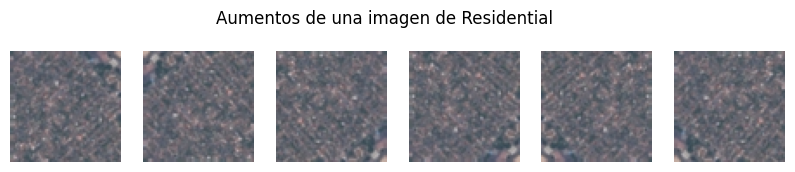

In [ ]:
# Normalización sin fuga de información: estadísticos SOLO de entrenamiento
MU = X_train.reshape(-1, 3).mean(axis=0).astype("float32")
SIGMA = X_train.reshape(-1, 3).std(axis=0).astype("float32")
print("Media (train):", MU.round(2), "| Desviación (train):", SIGMA.round(2))


def augment(x):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.random_flip_up_down(x)
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    return tf.image.rot90(x, k)


def prep_scratch(x, y):
    return (tf.cast(x, tf.float32) - MU) / SIGMA, y


def prep_resnet(x, y):
    x = tf.image.resize(tf.cast(x, tf.float32), (IMG_TL, IMG_TL))
    return keras.applications.resnet50.preprocess_input(x), y


def make_ds(X, y, prep, training=False, aug=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    if aug:
        ds = ds.map(lambda a, b: (augment(a), b), num_parallel_calls=AUTOTUNE)
    return ds.map(prep, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)


# Conjuntos de evaluación (sin barajar ni aumentar): se usan para medir train/dev/test
eval_scratch = {n: make_ds(X, y, prep_scratch) for n, X, y in
                [("train", X_train, y_train), ("dev", X_dev, y_dev), ("test", X_test, y_test)]}
eval_resnet = {n: make_ds(X, y, prep_resnet) for n, X, y in
               [("train", X_train, y_train), ("dev", X_dev, y_dev), ("test", X_test, y_test)]}

# Vista rápida del aumento de datos
img = X_train[0]
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for ax in axes:
    ax.imshow(augment(tf.constant(img)).numpy()); ax.axis("off")
plt.suptitle(f"Aumentos de una imagen de {CLASSES[y_train[0]]}"); plt.show()

## 4. Utilidades de entrenamiento y evaluación

Para cada modelo se registra: exactitud en entrenamiento (sin aumento), exactitud en validación, **brecha**, F1 macro en validación, parámetros entrenables, tiempo por época y épocas usadas.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)


import re, unicodedata

def safe_name(name):
    """Nombre válido para Keras/TF: solo ASCII, sin acentos, espacios ni '+'."""
    n = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode("ascii")
    n = n.replace("+", "").replace(" ", "_")
    n = re.sub(r"[^A-Za-z0-9_.\-]", "", n)
    return re.sub(r"_+", "_", n).strip("_")


class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.t0)


def callbacks(name, patience=6):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
        keras.callbacks.ModelCheckpoint(f"{OUT_DIR}/{safe_name(name)}.keras", monitor="val_loss", save_best_only=True),
        EpochTimer(),
    ]


def predict_labels(model, ds):
    return np.argmax(model.predict(ds, verbose=0), axis=1)


models, histories, results = {}, {}, []


def fit_and_log(model, name, tecnica, train_ds, eval_sets, epochs, patience=6):
    cbs = callbacks(name, patience)
    hist = model.fit(train_ds, validation_data=eval_sets["dev"], epochs=epochs, callbacks=cbs, verbose=2)
    timer = cbs[-1]
    tr_acc = accuracy_score(y_train, predict_labels(model, eval_sets["train"])) * 100
    y_pred_dev = predict_labels(model, eval_sets["dev"])
    dv_acc = accuracy_score(y_dev, y_pred_dev) * 100
    _, _, f1, _ = precision_recall_fscore_support(y_dev, y_pred_dev, average="macro", zero_division=0)
    n_train = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    row = {"Técnica": tecnica, "Modelo": name, "Train (%)": round(tr_acc, 2), "Validación (%)": round(dv_acc, 2),
           "Brecha (pp)": round(tr_acc - dv_acc, 2), "F1 macro val": round(f1, 4),
           "Parámetros entrenables": n_train, "s/época": round(float(np.mean(timer.times)), 1),
           "Épocas": len(hist.history["loss"])}
    models[name], histories[name] = model, hist.history
    results[:] = [r for r in results if r["Modelo"] != name] + [row]
    print(f"\n{name:28s} train={tr_acc:6.2f}%  dev={dv_acc:6.2f}%  brecha={tr_acc-dv_acc:5.2f} pp  F1={f1:.4f}")
    return hist


def plot_curves(names, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for n in names:
        h = histories[n]
        l, = axes[0].plot(h["loss"], label=f"{n} train")
        axes[0].plot(h["val_loss"], "--", color=l.get_color(), label=f"{n} val")
        axes[1].plot(np.array(h["accuracy"]) * 100, color=l.get_color(), label=f"{n} train")
        axes[1].plot(np.array(h["val_accuracy"]) * 100, "--", color=l.get_color(), label=f"{n} val")
    axes[0].set_title("Pérdida (entropía cruzada)"); axes[0].set_xlabel("Época")
    axes[1].set_title("Exactitud (%)"); axes[1].set_xlabel("Época")
    axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    cm_n = cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(9, 7.5))
    sns.heatmap(cm_n, annot=cm, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, cbar_kws={"label": "proporción por fila"})
    plt.xlabel("Predicción"); plt.ylabel("Clase real"); plt.title(title)
    plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

## 5. Técnica 1 — CNN desde cero

Arquitectura: 4 bloques `Conv → BatchNorm → ReLU → Conv → BatchNorm → ReLU → MaxPool` con 32, 64, 128 y 256 filtros,
Global Average Pooling, una capa densa de 256 unidades y softmax de 10 clases. Inicialización **He**, igual que en la práctica.

**Experimento controlado:** solo cambia la regularización. Se mantienen fijos los datos, la arquitectura, la inicialización, el optimizador y el máximo de épocas.

| Variante | L2 (λ) | Dropout | Aumento |
|---|---|---|---|
| Sin regularización | 0 | 0 | No |
| L2 + Dropout | 1e-4 | 0.3 (conv) / 0.5 (densa) | No |
| L2 + Dropout + Aumento | 1e-4 | 0.3 / 0.5 | Sí |

Keras suma la penalización L2 (λ·Σ‖W‖²) al costo y su gradiente (2λW) a cada `dW` automáticamente; el dropout es invertido y se desactiva solo en validación, prueba y predicción.

In [ ]:
def build_cnn(l2=0.0, drop_conv=0.0, drop_dense=0.0, name="cnn"):
    reg = regularizers.l2(l2) if l2 > 0 else None
    init = "he_normal"
    inp = keras.Input((64, 64, 3))
    x = inp
    for filters in (32, 64, 128, 256):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_initializer=init, kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
        if drop_conv > 0:
            x = layers.Dropout(drop_conv)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu", kernel_initializer=init, kernel_regularizer=reg)(x)
    if drop_dense > 0:
        x = layers.Dropout(drop_dense)(x)
    out = layers.Dense(10, activation="softmax", dtype="float32")(x)
    model = keras.Model(inp, out, name=name)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


build_cnn().summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             

 Total params: 1,243,498 (4.74 MB)

 Trainable params: 1,241,578 (4.74 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
cnn_settings = {
    "CNN sin regularización":   dict(l2=0.0,  drop_conv=0.0, drop_dense=0.0, aug=False),
    "CNN L2 + Dropout":         dict(l2=1e-4, drop_conv=0.3, drop_dense=0.5, aug=False),
    "CNN L2 + Dropout + Aumento": dict(l2=1e-4, drop_conv=0.3, drop_dense=0.5, aug=True),
}

for name, cfg in cnn_settings.items():
    print("=" * 80, "\n", name)
    keras.utils.set_random_seed(SEED)          # misma inicialización en las tres variantes
    cfg = dict(cfg); aug = cfg.pop("aug")
    model = build_cnn(**cfg, name=safe_name(name))
    train_ds = make_ds(X_train, y_train, prep_scratch, training=True, aug=aug)
    fit_and_log(model, name, "1. CNN desde cero", train_ds, eval_scratch, EPOCHS_SCRATCH, patience=6)

 CNN sin regularización
Epoch 1/40
296/296 - 66s - 222ms/step - accuracy: 0.7273 - loss: 0.7751 - val_accuracy: 0.6657 - val_loss: 1.1976 - learning_rate: 0.0010
Epoch 2/40
296/296 - 6s - 21ms/step - accuracy: 0.8362 - loss: 0.4774 - val_accuracy: 0.8388 - val_loss: 0.4700 - learning_rate: 0.0010
Epoch 3/40
296/296 - 11s - 37ms/step - accuracy: 0.8787 - loss: 0.3612 - val_accuracy: 0.8733 - val_loss: 0.3611 - learning_rate: 0.0010
Epoch 4/40
296/296 - 5s - 17ms/step - accuracy: 0.9062 - loss: 0.2759 - val_accuracy: 0.8719 - val_loss: 0.3623 - learning_rate: 0.0010
Epoch 5/40
296/296 - 6s - 20ms/step - accuracy: 0.9212 - loss: 0.2298 - val_accuracy: 0.8341 - val_loss: 0.5428 - learning_rate: 0.0010
Epoch 6/40
296/296 - 10s - 35ms/step - accuracy: 0.9297 - loss: 0.2051 - val_accuracy: 0.8919 - val_loss: 0.3468 - learning_rate: 0.0010
Epoch 7/40
296/296 - 6s - 21ms/step - accuracy: 0.9360 - loss: 0.1838 - val_accuracy: 0.8551 - val_loss: 0.3949 - learning_rate: 0.0010
Epoch 8/40
296/296 -

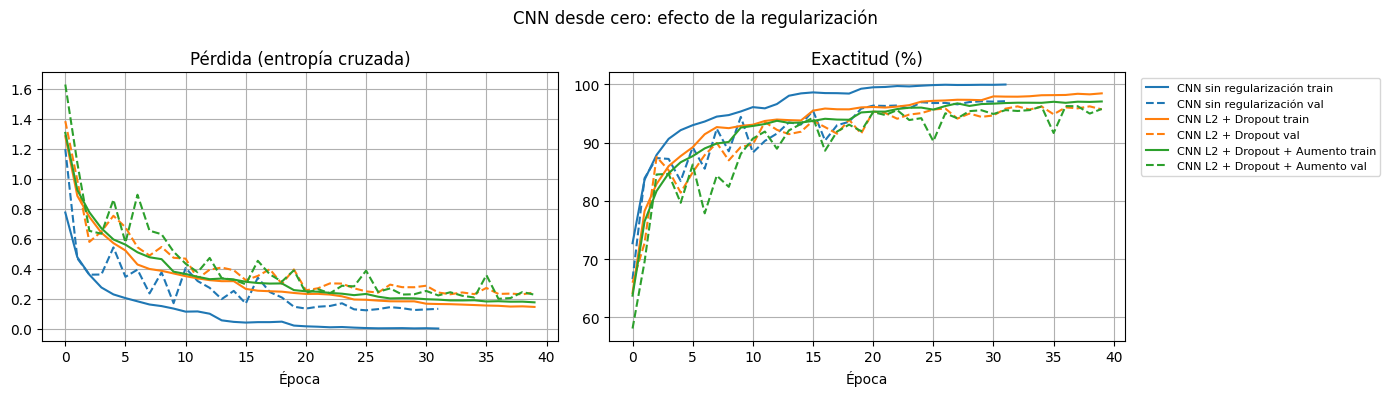

,Técnica,Train (%),Validación (%),Brecha (pp),F1 macro val,Parámetros entrenables,s/época,Épocas
Modelo,,,,,,,,
CNN sin regularización,1. CNN desde cero,99.98,96.77,3.22,0.9670,1241578,9.5,32
CNN L2 + Dropout,1. CNN desde cero,98.59,96.20,2.40,0.9610,1241578,7.2,40
CNN L2 + Dropout + Aumento,1. CNN desde cero,97.25,96.25,1.01,0.9623,1241578,8.6,40


In [ ]:
plot_curves(list(cnn_settings), "CNN desde cero: efecto de la regularización")
display(pd.DataFrame(results).set_index("Modelo"))

## 6. Técnica 2 — Transfer learning con ResNet-50 congelada

Se usa la técnica de la práctica ResNet-50 SIGNS: cargar ResNet-50 preentrenada en ImageNet **sin su última capa** (`include_top=False`),
**congelar** todas sus capas y entrenar solo una cabeza nueva (`GlobalAveragePooling → Dropout 0.3 → Dense 10 softmax`).
La base se llama con `training=False` para que BatchNorm use sus estadísticas de ImageNet.

In [ ]:
def build_resnet_tl():
    base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(IMG_TL, IMG_TL, 3))
    base.trainable = False
    inp = keras.Input((IMG_TL, IMG_TL, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(10, activation="softmax", dtype="float32")(x)
    model = keras.Model(inp, out, name="resnet50_tl")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base


keras.utils.set_random_seed(SEED)
tl_model, tl_base = build_resnet_tl()
print("Capas de la base:", len(tl_base.layers), "| entrenables:", sum(l.trainable for l in tl_base.layers))

train_resnet = make_ds(X_train, y_train, prep_resnet, training=True, aug=True)
fit_and_log(tl_model, "ResNet-50 transfer learning", "2. Transfer learning", train_resnet, eval_resnet, EPOCHS_TL, patience=4)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Capas de la base: 175 | entrenables: 0
Epoch 1/12
296/296 - 93s - 313ms/step - accuracy: 0.8783 - loss: 0.3777 - val_accuracy: 0.9395 - val_loss: 0.1807 - learning_rate: 0.0010
Epoch 2/12
296/296 - 44s - 149ms/step - accuracy: 0.9405 - loss: 0.1730 - val_accuracy: 0.9501 - val_loss: 0.1494 - learning_rate: 0.0010
Epoch 3/12
296/296 - 44s - 148ms/step - accuracy: 0.9461 - loss: 0.1538 - val_accuracy: 0.9560 - val_loss: 0.1332 - learning_rate: 0.0010
Epoch 4/12
296/296 - 44s - 149ms/step - accuracy: 0.9542 - loss: 0.1331 - val_accuracy: 0.9580 - val_loss: 0.1333 - learning_rate: 0.0010
Epoch 5/12
296/296 - 41s - 139ms/step - accuracy: 0.9567 - loss: 0.1250 - val_accuracy: 0.9585 - val_loss: 0.1263 - learning_rate: 0.0010
Epoch 6/12
296/296 - 44s - 149ms/step - accuracy: 0.9601 - loss: 0.1171 - val_accuracy: 0.9605 - val_loss: 0.1213 - learning_rate: 0.0010
Epoch 7/12
296/296 - 40s - 135ms/step - accuracy: 0.9615 - loss: 0.1115 - val_accu

## 7. Técnica 3 — Fine-tuning de ResNet-50

Se parte de los pesos del modelo anterior y se **descongela el último bloque residual (`conv5_*`)**.
Las capas de BatchNorm siguen congeladas y la base sigue en modo inferencia.
La tasa de aprendizaje baja a **1e-5** (100 veces menor) para ajustar sin destruir lo aprendido en ImageNet.

In [ ]:
# Mismo modelo que en la técnica 2, inicializado con sus pesos entrenados
ft_model, ft_base = build_resnet_tl()
ft_model.set_weights(tl_model.get_weights())

ft_base.trainable = True
for layer in ft_base.layers:
    layer.trainable = layer.name.startswith("conv5") and not isinstance(layer, layers.BatchNormalization)
print("Capas descongeladas en la base:", sum(l.trainable for l in ft_base.layers), "de", len(ft_base.layers))

ft_model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
fit_and_log(ft_model, "ResNet-50 fine-tuning", "3. Fine-tuning", train_resnet, eval_resnet, EPOCHS_FT, patience=4)

Capas descongeladas en la base: 22 de 175
Epoch 1/12
296/296 - 97s - 329ms/step - accuracy: 0.9688 - loss: 0.0905 - val_accuracy: 0.9672 - val_loss: 0.0981 - learning_rate: 1.0000e-05
Epoch 2/12
296/296 - 48s - 160ms/step - accuracy: 0.9766 - loss: 0.0697 - val_accuracy: 0.9679 - val_loss: 0.0939 - learning_rate: 1.0000e-05
Epoch 3/12
296/296 - 49s - 165ms/step - accuracy: 0.9786 - loss: 0.0626 - val_accuracy: 0.9681 - val_loss: 0.0889 - learning_rate: 1.0000e-05
Epoch 4/12
296/296 - 44s - 148ms/step - accuracy: 0.9817 - loss: 0.0544 - val_accuracy: 0.9704 - val_loss: 0.0926 - learning_rate: 1.0000e-05
Epoch 5/12
296/296 - 48s - 162ms/step - accuracy: 0.9843 - loss: 0.0466 - val_accuracy: 0.9756 - val_loss: 0.0820 - learning_rate: 1.0000e-05
Epoch 6/12
296/296 - 41s - 137ms/step - accuracy: 0.9872 - loss: 0.0386 - val_accuracy: 0.9681 - val_loss: 0.0863 - learning_rate: 1.0000e-05
Epoch 7/12
296/296 - 54s - 183ms/step - accuracy: 0.9868 - loss: 0.0384 - val_accuracy: 0.9731 - val_loss:

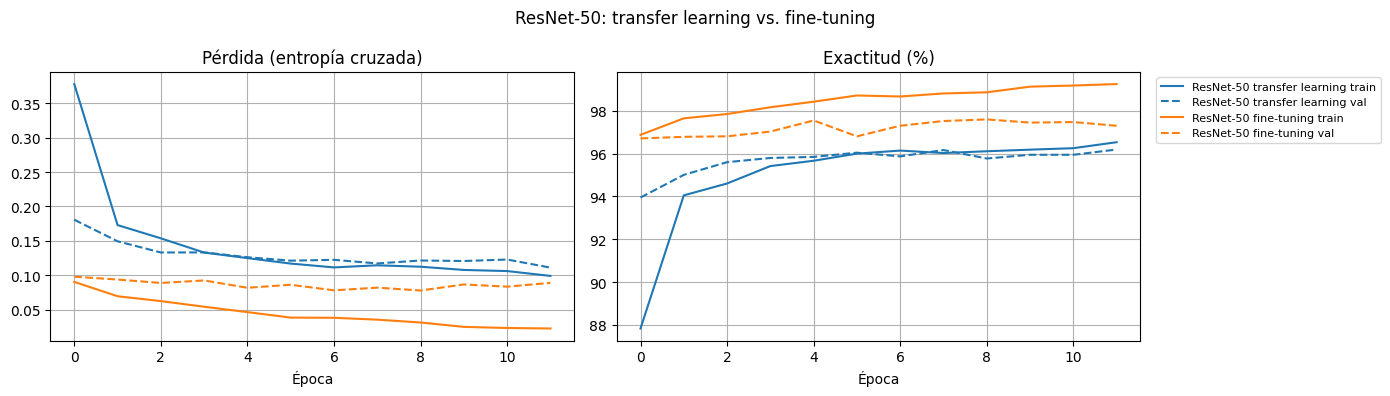

In [ ]:
plot_curves(["ResNet-50 transfer learning", "ResNet-50 fine-tuning"], "ResNet-50: transfer learning vs. fine-tuning")

## 8. Comparación de las tres técnicas (validación)

| Técnica | Modelo | Train | Validación | Brecha | F1 macro | Parámetros entrenables | s/época |
|---|---|---:|---:|---:|---:|---:|---:|

La tabla se genera a continuación con los resultados reales.

,Técnica,Train (%),Validación (%),Brecha (pp),F1 macro val,Parámetros entrenables,s/época,Épocas
Modelo,,,,,,,,
CNN sin regularización,1. CNN desde cero,99.98,96.77,3.22,0.9670,1241578,9.5,32
CNN L2 + Dropout,1. CNN desde cero,98.59,96.20,2.40,0.9610,1241578,7.2,40
CNN L2 + Dropout + Aumento,1. CNN desde cero,97.25,96.25,1.01,0.9623,1241578,8.6,40
ResNet-50 transfer learning,2. Transfer learning,98.01,96.20,1.81,0.9606,20490,47.1,12
ResNet-50 fine-tuning,3. Fine-tuning,99.41,97.60,1.81,0.9752,14973962,49.5,12


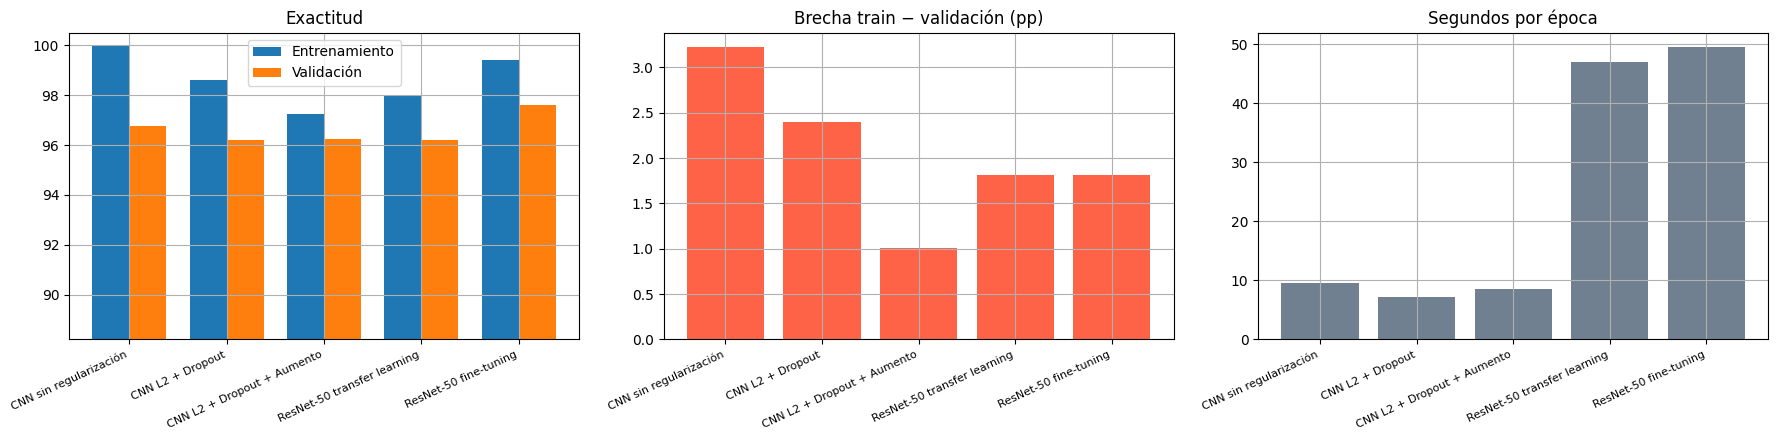

In [ ]:
tabla = pd.DataFrame(results).set_index("Modelo")
display(tabla)
tabla.to_csv(f"{OUT_DIR}/comparacion_validacion.csv")

names = tabla.index.tolist()
x = np.arange(len(names)); w = 0.38
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(x - w/2, tabla["Train (%)"], w, label="Entrenamiento")
axes[0].bar(x + w/2, tabla["Validación (%)"], w, label="Validación")
axes[0].set_ylim(max(0, tabla["Validación (%)"].min() - 8), 100.5)
axes[0].set_title("Exactitud"); axes[0].legend()
axes[1].bar(names, tabla["Brecha (pp)"], color="tomato"); axes[1].set_title("Brecha train − validación (pp)")
axes[2].bar(names, tabla["s/época"], color="slategray"); axes[2].set_title("Segundos por época")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=25, ha="right", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Reporte por clase en validación para cada técnica (mejor variante de la CNN, TL y FT)
for n in names:
    ds = eval_resnet["dev"] if n.startswith("ResNet") else eval_scratch["dev"]
    y_pred = predict_labels(models[n], ds)
    _, rec, f1, _ = precision_recall_fscore_support(y_dev, y_pred, labels=range(10), zero_division=0)
    print(f"{n:30s} peor clase (F1): {CLASSES[int(np.argmin(f1))]} = {f1.min():.3f}")

CNN sin regularización         peor clase (F1): PermanentCrop = 0.931
CNN L2 + Dropout               peor clase (F1): HerbaceousVegetation = 0.928
CNN L2 + Dropout + Aumento     peor clase (F1): HerbaceousVegetation = 0.909
ResNet-50 transfer learning    peor clase (F1): Highway = 0.931
ResNet-50 fine-tuning          peor clase (F1): PermanentCrop = 0.959


## 9. Selección y evaluación final en prueba

El modelo se elige con **validación** (mayor exactitud; en empate, mayor F1 macro).
El conjunto de prueba se consulta **una sola vez**, después de la selección.

Modelo seleccionado con validación: ResNet-50 fine-tuning

PRUEBA  exactitud=97.88%  precisión=0.9773  recall=0.9791  F1=0.9780  (macro)

                      precision    recall  f1-score   support

          AnnualCrop     0.9906    0.9333    0.9611       450
              Forest     0.9933    0.9844    0.9888       450
HerbaceousVegetation     0.9798    0.9711    0.9754       450
             Highway     0.9711    0.9840    0.9775       375
          Industrial     0.9841    0.9920    0.9880       375
             Pasture     0.9455    0.9833    0.9641       300
       PermanentCrop     0.9378    0.9653    0.9514       375
         Residential     0.9911    0.9933    0.9922       450
               River     0.9814    0.9867    0.9840       375
             SeaLake     0.9978    0.9978    0.9978       450

            accuracy                         0.9788      4050
           macro avg     0.9773    0.9791    0.9780      4050
        weighted avg     0.9791    0.9788    0.9788   

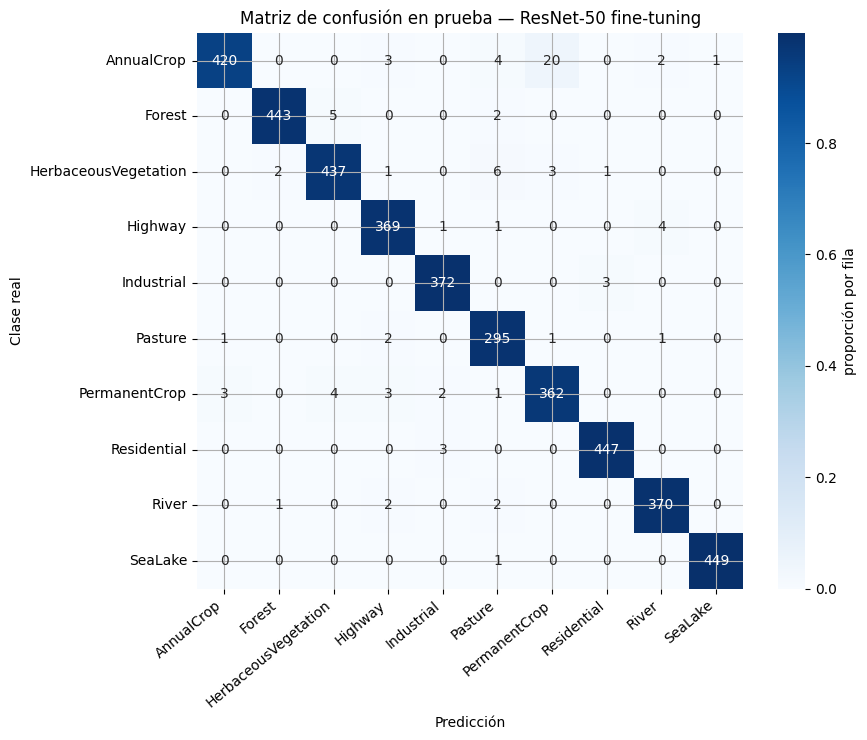

In [ ]:
best_name = tabla.sort_values(["Validación (%)", "F1 macro val"], ascending=False).index[0]
best_model = models[best_name]
test_ds = eval_resnet["test"] if best_name.startswith("ResNet") else eval_scratch["test"]
print("Modelo seleccionado con validación:", best_name)

y_pred_test = predict_labels(best_model, test_ds)
acc = accuracy_score(y_test, y_pred_test)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred_test, average="macro", zero_division=0)
print(f"\nPRUEBA  exactitud={acc*100:.2f}%  precisión={p:.4f}  recall={r:.4f}  F1={f1:.4f}  (macro)\n")
print(classification_report(y_test, y_pred_test, target_names=CLASSES, digits=4))
plot_confusion(y_test, y_pred_test, f"Matriz de confusión en prueba — {best_name}")

Confusiones más frecuentes (real -> predicha):
  AnnualCrop             -> PermanentCrop          20
  HerbaceousVegetation   -> Pasture                6
  Forest                 -> HerbaceousVegetation   5
  PermanentCrop          -> HerbaceousVegetation   4
  Highway                -> River                  4
  AnnualCrop             -> Pasture                4


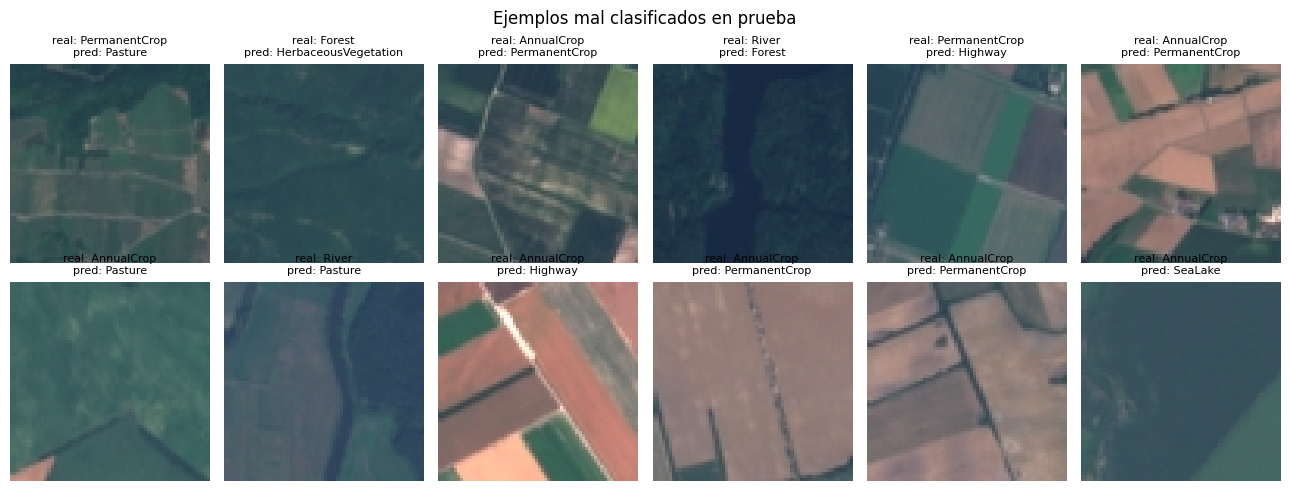

In [ ]:
# Pares de clases más confundidos y ejemplos mal clasificados
cm = confusion_matrix(y_test, y_pred_test)
np.fill_diagonal(cm, 0)
pares = sorted(((cm[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if cm[i, j]), reverse=True)[:6]
print("Confusiones más frecuentes (real -> predicha):")
for n, a, b in pares:
    print(f"  {a:22s} -> {b:22s} {n}")

err = np.where(y_pred_test != y_test)[0]
sel = np.random.default_rng(SEED).choice(err, min(12, len(err)), replace=False) if len(err) else []
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_test[i]); ax.set_title(f"real: {CLASSES[y_test[i]]}\npred: {CLASSES[y_pred_test[i]]}", fontsize=8)
plt.suptitle("Ejemplos mal clasificados en prueba"); plt.tight_layout(); plt.show()

In [ ]:
print(f"""
RESUMEN DEL SEGUNDO AVANCE
- Mejor variante de CNN desde cero: {tabla[tabla['Técnica'].str.startswith('1')]['Validación (%)'].idxmax()}
- Exactitud en validación por técnica:
{tabla[['Técnica', 'Validación (%)', 'Brecha (pp)', 'F1 macro val']].to_string()}
- Modelo seleccionado: {best_name}
- Prueba: exactitud {acc*100:.2f}%, F1 macro {f1:.4f}
""")


RESUMEN DEL SEGUNDO AVANCE
- Mejor variante de CNN desde cero: CNN sin regularización
- Exactitud en validación por técnica:
                                          Técnica  Validación (%)  Brecha (pp)  F1 macro val
Modelo                                                                                      
CNN sin regularización          1. CNN desde cero           96.77         3.22        0.9670
CNN L2 + Dropout                1. CNN desde cero           96.20         2.40        0.9610
CNN L2 + Dropout + Aumento      1. CNN desde cero           96.25         1.01        0.9623
ResNet-50 transfer learning  2. Transfer learning           96.20         1.81        0.9606
ResNet-50 fine-tuning              3. Fine-tuning           97.60         1.81        0.9752
- Modelo seleccionado: ResNet-50 fine-tuning
- Prueba: exactitud 97.88%, F1 macro 0.9780

